In [1]:
import sys
sys.path.insert(0, "..")

from utils.modelling import *
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

In [2]:
Xtrain, ytrain, Xval, yval, Xtest, ytest = load_train_val_test('../data/processed/dataset.csv')

In [3]:
weights = make_class_weights(ytrain)
FOREST_PARAMS_A = {"max_depth": None, "min_samples_leaf": 10, "max_features": 0.3, "class_weight": weights(0.5)}
FOREST_PARAMS_B = {"max_depth": None, "min_samples_leaf": 10, "max_features": 0.3, "class_weight": weights(0.5)}

regression_model_A = make_pipeline(
    make_preprocessor(model="A"),
    LogisticRegression(class_weight=weights(0.5), max_iter=1000)
).fit(Xtrain, ytrain)

forest_model_A = make_pipeline(
    make_preprocessor(model="A"),
    RandomForestClassifier(n_estimators=100, random_state=67, n_jobs=-1, **FOREST_PARAMS_A)
).fit(Xtrain, ytrain)

forest_model_B = make_pipeline(
    make_preprocessor(model="B"),
    RandomForestClassifier(n_estimators=100, random_state=67, n_jobs=-1, **FOREST_PARAMS_B)
).fit(Xtrain, ytrain)

In [4]:
feature_names = regression_model_A.named_steps["columntransformer"].get_feature_names_out()
coefficients = pd.DataFrame(regression_model_A.named_steps["logisticregression"].coef_.T, index=feature_names, columns=LABELS)
coefficients["Subst vs None"] = coefficients["Subst/Destroyed"] - coefficients["None"]
coefficients["Minor vs None"] = coefficients["Minor"] - coefficients["None"]
coefficients["Subst vs None odds ratio"] = np.exp(coefficients["Subst vs None"])
coefficients.to_csv("../results/lr_coefficients.csv")

ranked = coefficients.sort_values("Subst vs None")
pd.concat([ranked.head(10), ranked.tail(10)])[["Subst vs None", "Subst vs None odds ratio", "Minor vs None"]].round(3)

,Subst vs None,Subst vs None odds ratio,Minor vs None
nom__SpeciesGroup_Caprimulgiformes,-2.455,0.086,-0.522
nom__PHASE_OF_FLIGHT_Local,-1.784,0.168,-0.178
nom__FAAREGION_ANE,-1.768,0.171,-0.502
nom__SpeciesGroup_Passeriformes,-1.275,0.279,-0.896
nom__PHASE_OF_FLIGHT_missing,-1.191,0.304,0.037
nom__TYPE_ENG_missing,-1.153,0.316,-1.153
nom__PRECIPITATION_snow,-1.101,0.333,-0.895
nom__SpeciesGroup_Unknown,-0.992,0.371,-0.662
nom__PHASE_OF_FLIGHT_Taxi,-0.898,0.407,-1.173
nom__AC_CLASS_infrequent_sklearn,-0.887,0.412,-0.693


In [5]:
FEATURES_A = NUMERIC + ORDINAL + NOMINAL
FEATURES_B = FEATURES_A + STRIKE_PARTS

importance = {}
for name, model, features in [("Random forest A", forest_model_A, FEATURES_A), ("Random forest B", forest_model_B, FEATURES_B), ("Logistic regression A", regression_model_A, FEATURES_A)]:
    result = permutation_importance(model, Xval[features], yval, scoring="f1_macro", n_repeats=5, random_state=67, n_jobs=-1)
    importance[name] = pd.DataFrame({"mean": result.importances_mean, "std": result.importances_std}, index=features).sort_values("mean", ascending=False)
    importance[name].to_csv(f"../results/permutation_importance_{name.lower().replace(' ', '_')}.csv")

pd.concat({name: table["mean"] for name, table in importance.items()}, axis=1).sort_values("Random forest A", ascending=False).round(4)

,Random forest A,Random forest B,Logistic regression A
SIZE,0.0544,0.0637,0.0760
BodyMass,0.0350,-0.0004,0.0045
AC_MASS,0.0265,0.0133,0.0326
HEIGHT,0.0178,0.0030,0.0014
PHASE_OF_FLIGHT,0.0151,0.0186,0.0196
SPEED,0.0114,0.0010,0.0052
log_ImpactEnergy,0.0104,-0.0004,0.0016
TIME_OF_DAY,0.0096,0.0079,0.0025
TYPE_ENG,0.0077,0.0035,0.0103
PRECIPITATION,0.0063,0.0041,0.0053


In [6]:
BEST_MODEL_A = forest_model_A
predicted = pd.Series(BEST_MODEL_A.predict(Xtest), index=Xtest.index).map(dict(enumerate(LABELS)))
actual = ytest.map(dict(enumerate(LABELS)))

def describe_strikes(X):
    return pd.Series({
        "strikes": len(X),
        "median SPEED (kt)": X["SPEED"].median(),
        "median HEIGHT (ft)": X["HEIGHT"].median(),
        "BodyMass missing (%)": X["BodyMass"].isna().mean() * 100,
        "SIZE = Large (%)": (X["SIZE"] == "Large").mean() * 100,
        "SIZE missing (%)": X["SIZE"].isna().mean() * 100,
        "median AC_MASS": X["AC_MASS"].median(),
        "most common phase": X["PHASE_OF_FLIGHT"].mode().iloc[0] if X["PHASE_OF_FLIGHT"].notna().any() else None,
    })

misclassified = pd.DataFrame({
    "Subst/Destroyed caught": describe_strikes(Xtest[(actual == "Subst/Destroyed") & (predicted == "Subst/Destroyed")]),
    "Subst/Destroyed called None": describe_strikes(Xtest[(actual == "Subst/Destroyed") & (predicted == "None")]),
    "Subst/Destroyed called Minor": describe_strikes(Xtest[(actual == "Subst/Destroyed") & (predicted == "Minor")]),
    "None called Subst/Destroyed": describe_strikes(Xtest[(actual == "None") & (predicted == "Subst/Destroyed")]),
    "None correctly None": describe_strikes(Xtest[(actual == "None") & (predicted == "None")]),
})
misclassified.to_csv("../results/misclassified.csv")
misclassified

,Subst/Destroyed caught,Subst/Destroyed called None,Subst/Destroyed called Minor,None called Subst/Destroyed,None correctly None
strikes,124,128,41,232,23457
median SPEED (kt),125.0,135.0,100.0,130.0,140.0
median HEIGHT (ft),900.0,35.0,500.0,550.0,50.0
BodyMass missing (%),25.0,57.8125,60.97561,27.586207,58.937631
SIZE = Large (%),67.741935,25.78125,63.414634,51.724138,2.293558
SIZE missing (%),3.225806,21.875,2.439024,3.448276,18.987935
median AC_MASS,2.0,4.0,1.0,3.0,4.0
most common phase,En Route,Approach,Approach,Climb,Approach


## plots

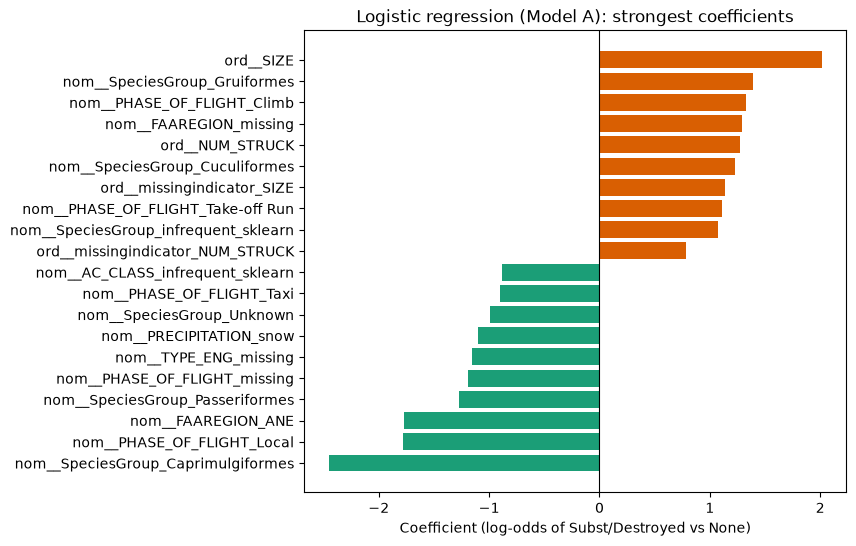

In [7]:
import matplotlib.pyplot as plt

top = pd.concat([ranked.head(10), ranked.tail(10)])["Subst vs None"]
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index, top.values, color=["#1b9e77" if v < 0 else "#d95f02" for v in top.values])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coefficient (log-odds of Subst/Destroyed vs None)")
ax.set_title("Logistic regression (Model A): strongest coefficients")
fig.savefig("../plots/lr_coefficients.png", dpi=200, bbox_inches="tight")

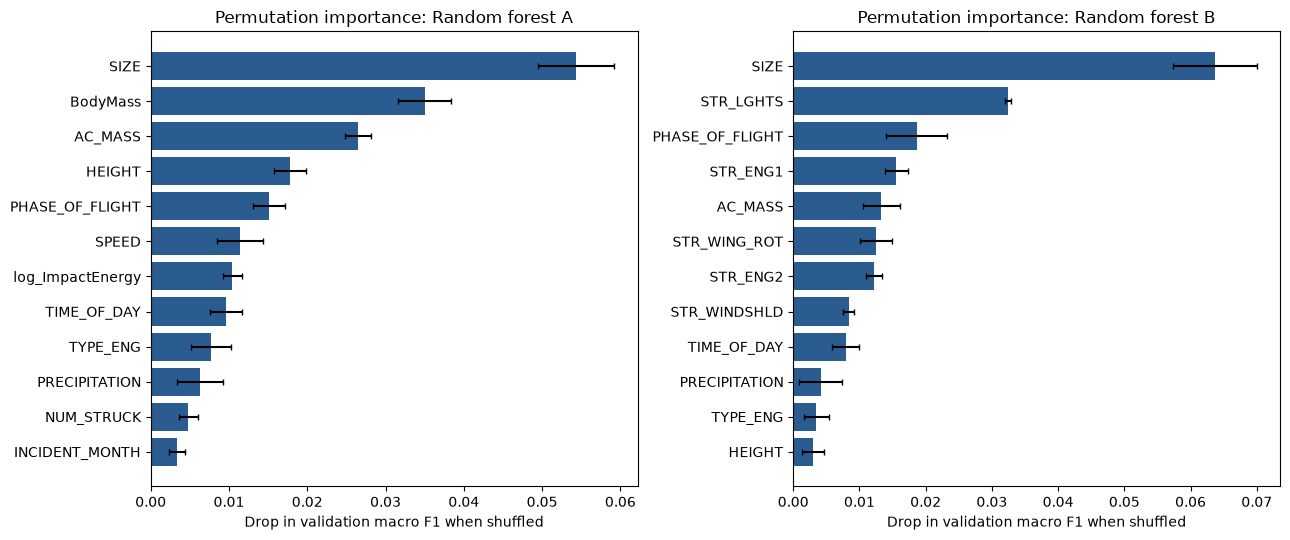

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, name in zip(axes, ["Random forest A", "Random forest B"]):
    table = importance[name].head(12)[::-1]
    ax.barh(table.index, table["mean"], xerr=table["std"], capsize=2, color="#2b5c8f")
    ax.set_xlabel("Drop in validation macro F1 when shuffled")
    ax.set_title(f"Permutation importance: {name}")
fig.tight_layout()
fig.savefig("../plots/permutation_importance.png", dpi=200, bbox_inches="tight")